# 03 — Exploratory data analysis

Purpose: describe the samples, the treatment (pre-crisis energy intensity) and the outcomes,
and take a first, purely descriptive look at whether more and less energy-intensive firms
moved in parallel before 2022. No causal claims are made here; those come from the
models in `04_h1.ipynb` and `05_h2.ipynb`.

**Samples** (defined in `src/sample.py`):
* **H1 sample**: non-financial STOXX Europe 600 firms (2021 constituents) with carbon intensity
  before and after 2022 and pre-crisis energy intensity.
* **H2 sample**: the industrial firms (NACE 05-39) of the H1 sample with a sector producer price index.

**Key variables**
* `ln_ci` = ln(Scope 1+2 emissions / revenue), t CO2e per EUR million (H1 outcome)
* `exposure` = mean energy use / revenue, 2016-2019 (treatment); `high_exposure` = above sample median
* `ln_emissions`, `ln_real_revenue`, `ln_real_ci` (H2 outcomes; real = deflated with sector PPI, 2021 = 100)

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sample as S

TAB, FIG = Path("output/tables"), Path("output/figures")
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COL = {0: "#4C72B0", 1: "#C44E52"}
LAB = {0: "Low pre-crisis energy intensity", 1: "High pre-crisis energy intensity"}

p = S.load_panel()
h1 = S.main_sample(p)
h2 = S.industry_sample(p)
print(f"H1 sample: {h1.ric.nunique()} firms, {len(h1)} firm-years")
print(f"H2 sample: {h2.ric.nunique()} firms, {len(h2)} firm-years")

H1 sample: 387 firms, 3214 firm-years
H2 sample: 230 firms, 1936 firm-years


## 1. Sample composition

In [2]:
firms = h1.drop_duplicates("ric")
comp = pd.DataFrame({
    "Firms": firms.groupby("country").ric.count(),
    "High exposure": firms.groupby("country").high_exposure.sum(),
}).sort_values("Firms", ascending=False)
comp.to_csv(TAB / "eda_sample_by_country.csv")
comp.head(12)

,Firms,High exposure
country,,
United Kingdom,81,36
France,54,23
Germany,47,22
Switzerland,41,16
Sweden,30,16
Netherlands,22,9
Italy,20,13
Spain,19,14
Finland,14,8


In [3]:
sect = (firms.assign(sector=firms.nace_label.str.replace(r" \(NACE\).*", "", regex=True).str[:55])
        .groupby(["nace2", "sector"]).agg(firms=("ric", "count"), median_exposure=("exposure", "median"),
                                           share_high=("high_exposure", "mean"))
        .reset_index().groupby("nace2").agg(firms=("firms", "sum"), median_exposure=("median_exposure", "median"),
                                            share_high=("share_high", "mean"), example=("sector", "first"))
        .sort_values("median_exposure", ascending=False))
sect.to_csv(TAB / "eda_exposure_by_nace2.csv")
sect.head(15)

,firms,median_exposure,share_high,example
nace2,,,,
17,7,"18,087.286",1.000,Manufacture of corrugated paper and paperboard...
23,4,"17,137.893",1.000,Manufacture of cement
50,3,"15,713.417",0.667,Sea and coastal freight water transport
51,2,"14,521.219",1.000,Passenger air transport
09,2,"14,203.865",0.500,Support activities for petroleum and natural g...
07,9,"6,909.965",1.000,Mining of iron ores
55,3,"5,830.600",1.000,Hotels and similar accommodation
79,1,"5,819.352",1.000,Tour operator activities
24,12,"4,963.509",1.000,Aluminium production


## 2. Treatment: distribution of pre-crisis energy intensity

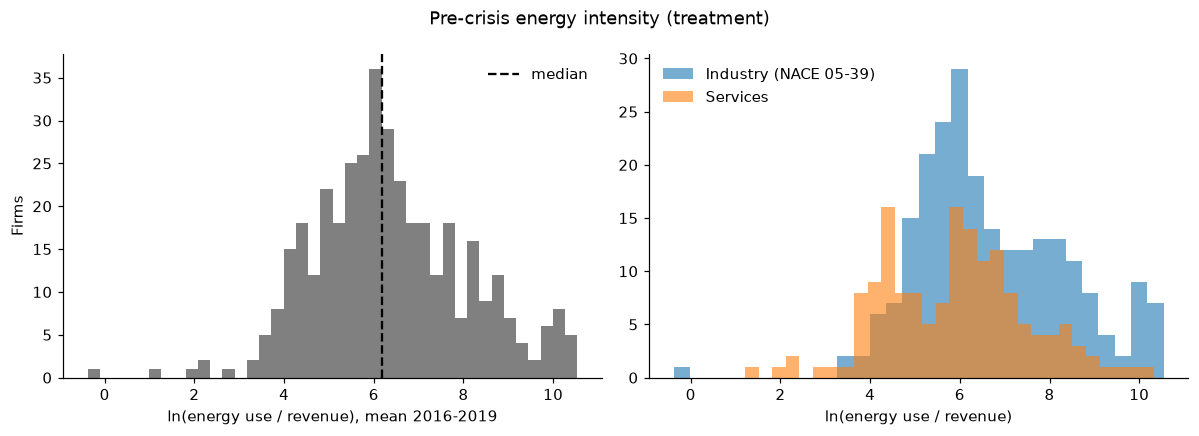

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(np.log(firms.exposure), bins=40, color="grey")
ax[0].axvline(np.log(firms.exposure.median()), color="k", ls="--", label="median")
ax[0].set_xlabel("ln(energy use / revenue), mean 2016-2019"); ax[0].set_ylabel("Firms"); ax[0].legend(frameon=False)
ind = firms.industry.map({True: "Industry (NACE 05-39)", False: "Services"})
for k, g in firms.groupby(ind):
    ax[1].hist(np.log(g.exposure), bins=30, alpha=0.6, label=k)
ax[1].set_xlabel("ln(energy use / revenue)"); ax[1].legend(frameon=False)
fig.suptitle("Pre-crisis energy intensity (treatment)")
fig.tight_layout(); fig.savefig(FIG / "eda_exposure_distribution.pdf"); plt.show()

## 3. Descriptive statistics (pre-crisis period 2016-2021)
Means by exposure group with a simple difference test (Welch t-test on firm-level means).
Large level differences are expected and are absorbed by firm fixed effects; what matters for
identification is whether the groups follow parallel *trends* (Section 4).

In [5]:
from scipy import stats

def firm_means(df, cols):
    return df[df.fyear.isin(S.PRE)].groupby(["ric", "high_exposure"])[cols].mean().reset_index()

df = h1.assign(emissions_kt=h1.scope12_total / 1e3, revenue_bn=h1.revenue / 1e9,
               assets_bn=h1.total_assets / 1e9)
cols = ["emissions_kt", "revenue_bn", "assets_bn", "carbon_intensity", "energy_intensity", "ln_ci"]
fm = firm_means(df, cols)
rows = []
for c in cols:
    a, b = fm.loc[fm.high_exposure == 0, c].dropna(), fm.loc[fm.high_exposure == 1, c].dropna()
    rows.append({"variable": c, "mean_low": a.mean(), "mean_high": b.mean(), "diff": b.mean() - a.mean(),
                 "p_value": stats.ttest_ind(b, a, equal_var=False).pvalue, "sd_all": fm[c].std(),
                 "N_low": len(a), "N_high": len(b)})
desc = pd.DataFrame(rows).set_index("variable")
desc.to_csv(TAB / "eda_descriptives_pre.csv")
desc

,mean_low,mean_high,diff,p_value,sd_all,N_low,N_high
variable,,,,,,,
emissions_kt,397.152,"7,596.211","7,199.060",0.000,"15,341.487",194,193
revenue_bn,13.527,16.018,2.492,0.381,27.906,194,193
assets_bn,23.288,27.499,4.211,0.385,47.605,194,193
carbon_intensity,23.439,445.969,422.531,0.000,715.205,194,193
energy_intensity,208.870,"4,764.079","4,555.209",0.000,"5,713.473",193,192
ln_ci,2.424,4.943,2.519,0.000,1.829,194,193


In [6]:
summ = h1[["scope12_total", "revenue", "total_assets", "carbon_intensity", "energy_intensity"]].describe(
    percentiles=[.01, .25, .5, .75, .99]).T
summ.to_csv(TAB / "eda_summary_all_years.csv")
summ

,count,mean,std,min,1%,25%,50%,75%,99%,max
scope12_total,"3,214.000","3,885,319.312","14,615,272.557",20.000,186.680,"43,851.500","210,416.000","1,051,716.000","78,435,000.000","194,800,000.000"
revenue,"3,214.000","16,769,041,023.300","32,042,131,443.055","79,307,924.682","197,249,683.586","2,378,106,842.042","5,727,635,466.147","18,087,833,550.508","178,561,533,302.199","356,299,801,600.000"
total_assets,"3,214.000","28,075,625,321.667","51,769,555,978.987","135,236,150.568","460,366,848.160","4,547,750,000.000","10,196,926,986.273","28,624,750,000.000","259,991,080,000.000","632,905,000,000.000"
carbon_intensity,"3,214.000",204.734,652.574,0.000,0.499,11.902,29.765,108.737,"3,461.388","9,882.796"
energy_intensity,"3,018.000","3,099.230","46,743.234",0.343,4.906,154.696,404.272,"1,387.363","27,822.967","2,552,776.712"


## 4. Outcome trends by exposure group (descriptive pre-trend check)
Mean outcome per group and year, expressed relative to the group's 2019 value
(reference year), with 95% confidence bands. Parallel lines before 2022 support the
identifying assumption; a divergence after 2022 is the pattern H1 predicts.

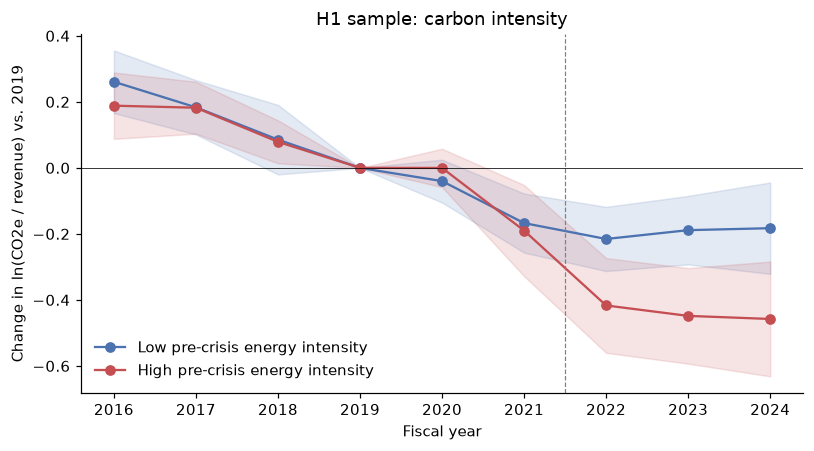

high_exposure,0,1,gap
fyear,,,
2016,0.261,0.188,-0.072
2017,0.183,0.182,-0.001
2018,0.086,0.079,-0.007
2019,0.000,0.000,0.000
2020,-0.040,-0.000,0.040
2021,-0.167,-0.190,-0.023
2022,-0.215,-0.417,-0.201
2023,-0.189,-0.448,-0.260
2024,-0.183,-0.458,-0.275


In [7]:
def group_trend(df, var, ref=S.REF_YEAR):
    """Within-firm change relative to the firm's own reference-year value, averaged by group."""
    base = df[df.fyear == ref].set_index("ric")[var]
    d = df[df.ric.isin(base.index)].copy()
    d["rel"] = d[var] - d.ric.map(base)
    g = d.groupby(["high_exposure", "fyear"]).rel.agg(["mean", "sem", "count"]).reset_index()
    g["lo"], g["hi"] = g["mean"] - 1.96 * g["sem"], g["mean"] + 1.96 * g["sem"]
    return g


def plot_trend(df, var, title, ylabel, fname, ax=None):
    g = group_trend(df, var)
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for k in [0, 1]:
        s = g[g.high_exposure == k]
        ax.plot(s.fyear, s["mean"], marker="o", color=COL[k], label=LAB[k])
        ax.fill_between(s.fyear, s.lo, s.hi, color=COL[k], alpha=0.15)
    ax.axvline(2021.5, color="grey", lw=0.8, ls="--"); ax.axhline(0, color="k", lw=0.5)
    ax.set_title(title); ax.set_xlabel("Fiscal year"); ax.set_ylabel(ylabel)
    if own:
        ax.legend(frameon=False, loc="lower left"); plt.tight_layout(); plt.savefig(FIG / fname); plt.show()
    return g

g_ci = plot_trend(h1, "ln_ci", "H1 sample: carbon intensity", "Change in ln(CO2e / revenue) vs. 2019",
                  "eda_trend_ln_ci.pdf")
g_ci.pivot(index="fyear", columns="high_exposure", values="mean").assign(gap=lambda x: x[1] - x[0])

### 4b. Decomposition: emissions vs. revenue (H1 sample)
Carbon intensity can fall because emissions fall or because (nominal) revenue rises.

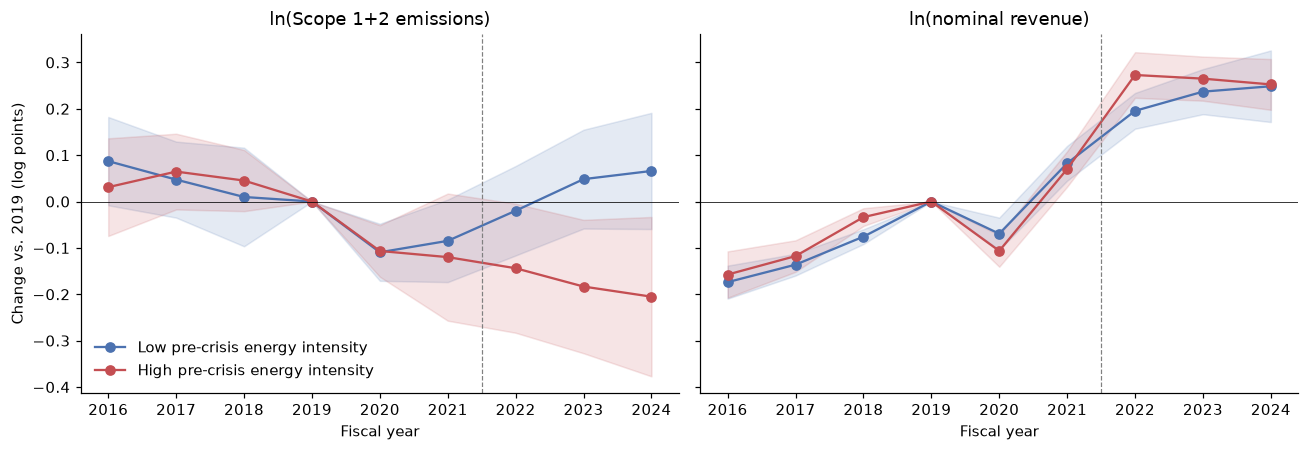

In [8]:
h1 = h1.assign(ln_revenue=np.log(h1.revenue.where(h1.revenue > 0)))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
plot_trend(h1, "ln_emissions", "ln(Scope 1+2 emissions)", "Change vs. 2019 (log points)", None, ax=axs[0])
plot_trend(h1, "ln_revenue", "ln(nominal revenue)", "", None, ax=axs[1])
axs[0].legend(frameon=False, loc="lower left"); fig.tight_layout(); fig.savefig(FIG / "eda_trend_decomposition_h1.pdf"); plt.show()

### 4c. H2 sample: real carbon intensity, emissions and real revenue

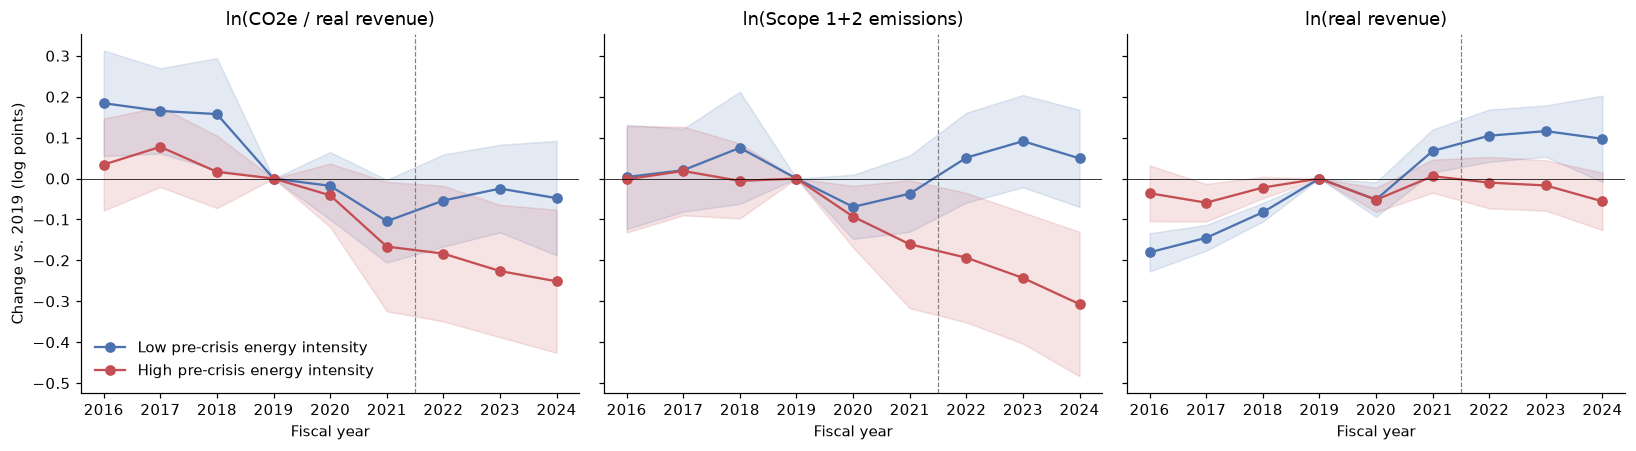

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
plot_trend(h2, "ln_real_ci", "ln(CO2e / real revenue)", "Change vs. 2019 (log points)", None, ax=axs[0])
plot_trend(h2, "ln_emissions", "ln(Scope 1+2 emissions)", "", None, ax=axs[1])
plot_trend(h2, "ln_real_revenue", "ln(real revenue)", "", None, ax=axs[2])
axs[0].legend(frameon=False, loc="lower left"); fig.tight_layout(); fig.savefig(FIG / "eda_trend_h2.pdf"); plt.show()

### 4d. Robustness of the picture: balanced panel and terciles

Balanced panel 2016-2024: 234 firms


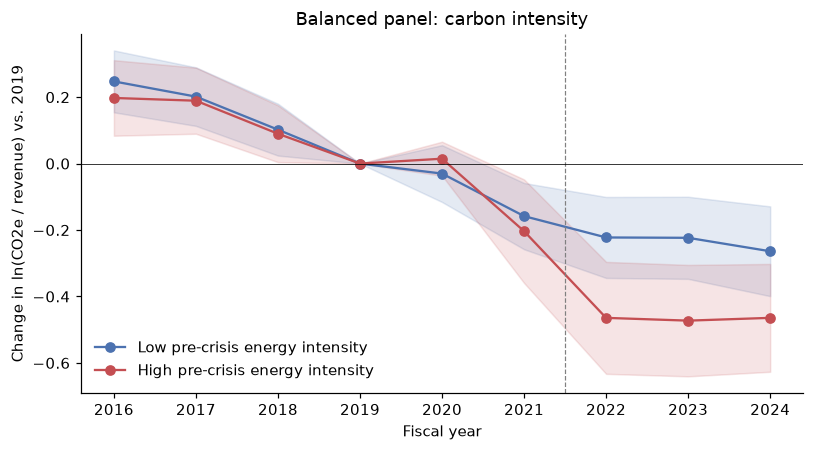

In [10]:
yrs = h1.groupby("ric").fyear.nunique()
bal = h1[h1.ric.isin(yrs[yrs == 9].index)]
print(f"Balanced panel 2016-2024: {bal.ric.nunique()} firms")
plot_trend(bal, "ln_ci", "Balanced panel: carbon intensity", "Change in ln(CO2e / revenue) vs. 2019",
           "eda_trend_ln_ci_balanced.pdf");

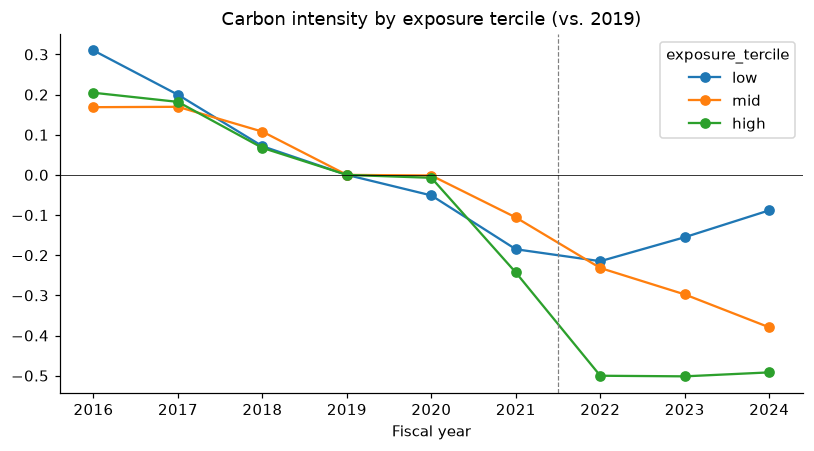

exposure_tercile,low,mid,high
fyear,,,
2016,0.310,0.169,0.205
2017,0.200,0.170,0.182
2018,0.071,0.108,0.067
2019,0.000,0.000,0.000
2020,-0.051,-0.002,-0.007
2021,-0.185,-0.106,-0.243
2022,-0.215,-0.232,-0.500
2023,-0.155,-0.298,-0.502
2024,-0.088,-0.380,-0.492


In [11]:
base = h1[h1.fyear == S.REF_YEAR].set_index("ric").ln_ci
t = h1[h1.ric.isin(base.index)].assign(rel=lambda d: d.ln_ci - d.ric.map(base))
tt = t.groupby(["exposure_tercile", "fyear"], observed=True).rel.mean().unstack(0)
ax = tt.plot(marker="o", figsize=(7.5, 4.2), title="Carbon intensity by exposure tercile (vs. 2019)")
ax.axvline(2021.5, color="grey", lw=0.8, ls="--"); ax.axhline(0, color="k", lw=0.5); ax.set_xlabel("Fiscal year")
plt.tight_layout(); plt.savefig(FIG / "eda_trend_terciles.pdf"); plt.show()
tt

## 5. Raw difference-in-differences (2x2, no controls)
Mean of the firm-level change in the outcome between the pre (2016-2021) and post (2022-2024)
period, by group. This is only a descriptive benchmark for the regression estimates.

In [12]:
def raw_did(df, var):
    fm = df.groupby(["ric", "high_exposure", "post"])[var].mean().unstack("post").dropna()
    fm["change"] = fm[1] - fm[0]
    g = fm.groupby("high_exposure").change.agg(["mean", "sem", "count"])
    a, b = fm.xs(0, level="high_exposure").change, fm.xs(1, level="high_exposure").change
    return {"outcome": var, "change_low": g.loc[0, "mean"], "change_high": g.loc[1, "mean"],
            "DiD": g.loc[1, "mean"] - g.loc[0, "mean"], "p_value": stats.ttest_ind(b, a, equal_var=False).pvalue,
            "firms": int(g["count"].sum())}

did = pd.DataFrame([raw_did(h1, v) for v in ["ln_ci", "ln_emissions", "ln_revenue"]] +
                   [dict(raw_did(h2, v), outcome=f"{v} (H2)") for v in ["ln_real_ci", "ln_emissions", "ln_real_revenue"]])
did.to_csv(TAB / "eda_raw_did.csv", index=False)
did

,outcome,change_low,change_high,DiD,p_value,firms
0,ln_ci,-0.253,-0.467,-0.214,0.002,387
1,ln_emissions,0.026,-0.150,-0.177,0.011,387
2,ln_revenue,0.280,0.317,0.037,0.190,387
3,ln_real_ci (H2),-0.107,-0.200,-0.093,0.243,230
4,ln_emissions (H2),0.063,-0.192,-0.255,0.002,230
5,ln_real_revenue (H2),0.170,0.008,-0.163,0.000,230


## 6. Quantitative pre-trend check (firm-level slopes)
For each firm, the linear trend of the outcome over 2016-2021 is estimated; the slopes are then
regressed on the exposure measure. A coefficient close to zero means that pre-crisis trends do
not differ systematically with energy intensity.

In [13]:
def firm_slopes(df, var):
    pre = df[df.fyear.isin(S.PRE)].dropna(subset=[var])
    out = []
    for ric, g in pre.groupby("ric"):
        if g.fyear.nunique() >= 3:
            out.append((ric, np.polyfit(g.fyear, g[var], 1)[0]))
    return pd.DataFrame(out, columns=["ric", "slope"]).merge(
        df.drop_duplicates("ric")[["ric", "exposure_std", "high_exposure"]], on="ric")

rows = []
for name, df, var in [("H1: ln_ci", h1, "ln_ci"), ("H1: ln_emissions", h1, "ln_emissions"),
                      ("H2: ln_real_ci", h2, "ln_real_ci")]:
    sl = firm_slopes(df, var)
    lr_c = stats.linregress(sl.exposure_std, sl.slope)
    lr_d = stats.linregress(sl.high_exposure, sl.slope)
    rows.append({"outcome": name, "firms": len(sl),
                 "slope_on_exposure_std": lr_c.slope, "p_cont": lr_c.pvalue,
                 "slope_high_minus_low": lr_d.slope, "p_dummy": lr_d.pvalue})
pt = pd.DataFrame(rows)
pt.to_csv(TAB / "eda_pretrend_slopes.csv", index=False)
pt

,outcome,firms,slope_on_exposure_std,p_cont,slope_high_minus_low,p_dummy
0,H1: ln_ci,384,-0.009,0.533,-0.000,0.994
1,H1: ln_emissions,384,-0.015,0.326,-0.012,0.680
2,H2: ln_real_ci,229,0.021,0.074,0.028,0.235


## 7. Outliers and data quality

In [14]:
q = h1.ln_ci.quantile([.001, .01, .99, .999])
print("ln_ci quantiles:", q.round(2).to_dict())
jump = h1.sort_values(["ric", "fyear"]).assign(d=lambda d: d.groupby("ric").ln_ci.diff())
big = jump[jump.d.abs() > np.log(3)]
print(f"Year-on-year changes in carbon intensity larger than factor 3: {len(big)} firm-years "
      f"({big.ric.nunique()} firms)")
big[["ric", "name", "fyear", "scope12_total", "revenue", "d"]].sort_values("d").head(15)

ln_ci quantiles: {0.001: -6.86, 0.01: -0.69, 0.99: 8.15, 0.999: 8.9}
Year-on-year changes in carbon intensity larger than factor 3: 73 firm-years (53 firms)


,ric,name,fyear,scope12_total,revenue,d
2459,SBMO.AS,SBM Offshore N.V.,2021,"2,352.000","3,230,111,520.000",-7.856
998,EXOR.AS,EXOR NV,2019,26.000,"143,755,000,000.000",-5.872
2410,SAGAb.ST,Sagax AB,2021,36.000,"301,680,015.931",-5.618
2135,PNN.L,Pennon Group PLC,2020,"93,516.000","733,244,834.238",-3.153
1736,LPPP.WA,Lpp SA,2021,"16,370.600","3,063,212,587.992",-2.597
174,AKZO.AS,Akzo Nobel NV,2018,"288,900.000","9,256,000,000.000",-2.428
149,AIXGn.DE,Aixtron SE,2019,577.400,"259,627,000.000",-2.367
429,BBOXT.L,Tritax Big Box Reit PLC,2021,40.700,"225,880,359.873",-2.275
656,CLNX.MC,Cellnex Telecom S.a,2022,"51,541.000","3,495,180,000.000",-2.180
1855,MRON.L,Melrose Industries PLC,2023,"146,645.000","3,863,921,665.967",-1.811


Large jumps usually reflect changes in reporting boundaries or restatements. They are kept in the
main sample; robustness checks will winsorize carbon intensity at the 1st/99th percentile and
drop firm-years with jumps larger than a factor of three.